# Monte Carlo integration

Can random numbers help us evaluate a definite integral?

**Learning goal.** Turn a integral into a sample average. Compare repeated runs and explain how sample size changes the variability.

Run the cells from top to bottom. NumPy does the sampling and arithmetic. Matplotlib draws the figures. If needed, run **%pip install numpy matplotlib** in a new cell. Fixed seeds reproduce the classroom results. Change a seed for a fresh run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "grid.alpha": 0.25})
TEAL, BLUE, ORANGE = "#087F7D", "#376C9D", "#AD5124"

## 1. Estimate an integral by averaging heights

If $U$ is uniform on $[a,b]$, its density is $1/(b-a)$. The expected height is the integral divided by the interval width. Replace the expected height with the mean of $N$ sampled heights.

$$
\mathbb{E}[f(U)]=\frac{1}{b-a}\int_a^b f(x)\,dx,
\qquad
\widehat I_N=(b-a)\frac{1}{N}\sum_{i=1}^{N} f(U_i).
$$

**Easy example.** 
- For $f(x)=x^2$ on $[0,2]$, the exact answer is $[x^3/3]_0^2=8/3$. The gold rectangle below has width 2 and the sampled mean height. Its area equals the estimate.

Estimate = 2.73001   Exact = 2.66667   Absolute error = 0.06334


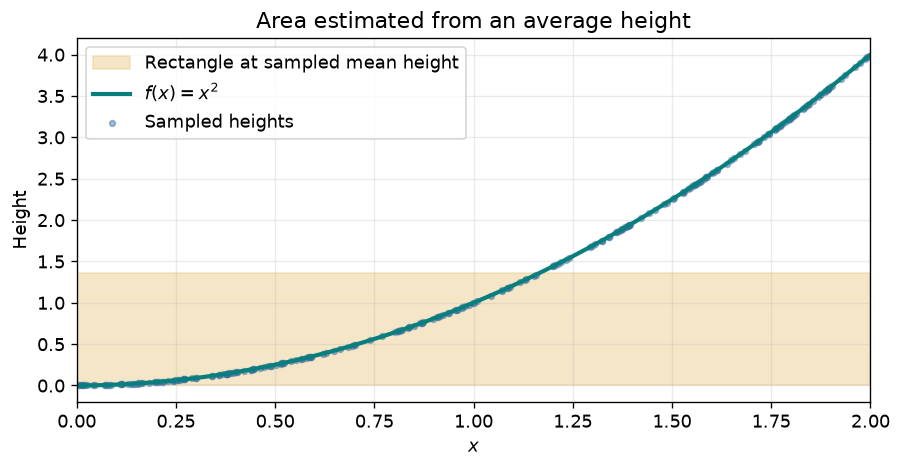

In [2]:
rng = np.random.default_rng(12)
u = rng.uniform(0, 2, size=250)
heights = u**2
area = 2 * heights.mean()
exact = 8/3
print(f"Estimate = {area:.5f}   Exact = {exact:.5f}   Absolute error = {abs(area-exact):.5f}")

grid = np.linspace(0, 2, 200)
fig, ax = plt.subplots(figsize=(7.4, 3.8), layout="constrained")
ax.fill_between([0, 2], heights.mean(), color="#EBC886", alpha=0.45,
                label="Rectangle at sampled mean height")
ax.plot(grid, grid**2, color=TEAL, linewidth=2.5, label="$f(x)=x^2$")
ax.scatter(u, heights, s=12, color=BLUE, alpha=0.45, label="Sampled heights")
ax.set(title="Area estimated from an average height", xlabel="$x$", ylabel="Height", xlim=(0, 2))
ax.grid()
ax.legend()

plt.show()

## 2. Repeat the experiment at several sample sizes

The **law of large numbers** says the sample mean approaches the expected value as $N$ grows. With independent samples and finite variance, the standard error of the mean is $\sigma/\sqrt{N}$. For this integral, we average the scaled heights $2U^2$, so $\sigma$ is the standard deviation of $2U^2$.

**Four times as many samples typically halves the sampling spread.** The error in a particular run can still increase. The box plots below show 80 independent runs per sample size. Compare their vertical spread around the exact answer.

N =   100   spread across runs (SD) = 0.24491
N =   400   spread across runs (SD) = 0.12472
N = 1,600   spread across runs (SD) = 0.05741
N = 6,400   spread across runs (SD) = 0.02761


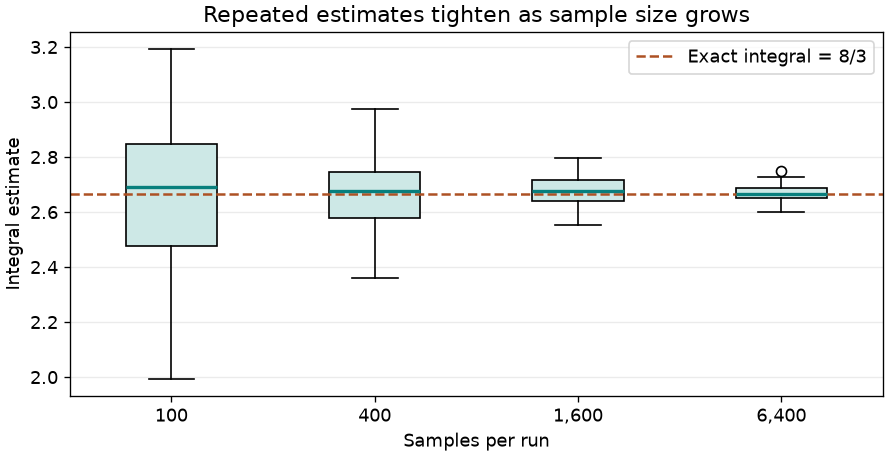

In [4]:
rng = np.random.default_rng(99)
sizes = [100, 400, 1600, 6400]
runs = [2 * (rng.uniform(0, 2, size=(80, n))**2).mean(axis=1) for n in sizes]

fig, ax = plt.subplots(figsize=(7.4, 3.8), layout="constrained")
ax.boxplot(runs, patch_artist=True, boxprops={"facecolor": "#CDE8E6"},
           medianprops={"color": TEAL, "linewidth": 2})
ax.set_xticks(range(1, len(sizes) + 1), [f"{n:,}" for n in sizes])
ax.axhline(exact, color=ORANGE, linestyle="--", label="Exact integral = 8/3")
ax.set(title="Repeated estimates tighten as sample size grows",
       xlabel="Samples per run", ylabel="Integral estimate")
ax.grid(axis="y")
ax.legend()
plt.show()

for n, estimates in zip(sizes, runs):
    print(f"N = {n:5,d}   spread across runs (SD) = {estimates.std(ddof=1):.5f}")

## 3. A 20-dimensional integral where Monte Carlo is practical

Take 20 independent inputs, each uniform from 0 to 1. Let $x_{21}=x_1$ so the last input pairs with the first. Average the products of neighbors, then measure how much that score exceeds $1/4$. Scores below the threshold contribute zero.

$$
g(x_1,\ldots,x_{20})
=\max\left(0,\frac1{20}\sum_{j=1}^{20} x_jx_{j+1}-\frac14\right),
\qquad
I=\int_{[0,1]^{20}}g(\mathbf{x})\,d\mathbf{x}.
$$

The integral is the **mean excess above the threshold**. Neighbor products share inputs, and the threshold applies to the whole sum. The integrand does not factor into independent one-variable terms. A full grid with 10 sample values on each axis would require $10^{20}$ evaluations. Monte Carlo draws complete 20-coordinate points directly. The cube has volume 1, so the estimate is the mean of $g$. Specialized methods could also be considered. Here Monte Carlo gives a short, practical approach without requiring an exact value.

Each row in the code is one point. **np.roll** lines up each input with its next neighbor, wrapping the last input back to the first.

In [5]:
def excess(points, threshold=0.25):
    neighbors = np.roll(points, -1, axis=1)
    score = (points * neighbors).mean(axis=1)
    return np.maximum(score - threshold, 0)


rng = np.random.default_rng(202)
points = rng.random((50_000, 20))
samples = excess(points)
estimate = samples.mean()
se = samples.std(ddof=1) / np.sqrt(samples.size)
print(f"Integral estimate: {estimate:.6f}")
print(f"Estimated standard error: {se:.6f}")
print(f"Approximate 95% interval: [{estimate-1.96*se:.6f}, {estimate+1.96*se:.6f}]")

Integral estimate: 0.026685
Estimated standard error: 0.000186
Approximate 95% interval: [0.026321, 0.027050]


The **standard error** measures sampling variability in the estimate. The approximate 95% interval uses a normal approximation for the sample mean. Over many runs, about 95% of intervals constructed this way should contain the true value when the approximation is good.

Each dot below represents one fresh run. The dashed line is an independent estimate using 50,000 points. **Compare.** Does the spread shrink even when we have no exact answer to plot?

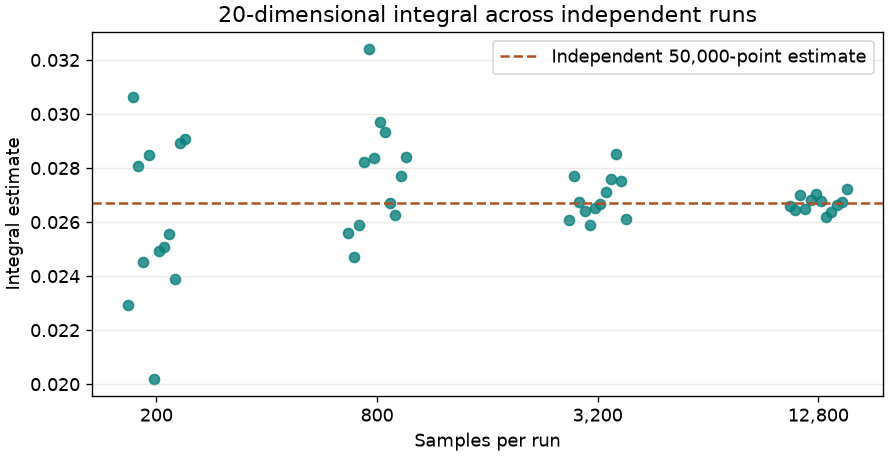

In [6]:
rng = np.random.default_rng(303)
sizes_20d = [200, 800, 3200, 12800]
repeats = [[excess(rng.random((n, 20))).mean() for _ in range(12)]
           for n in sizes_20d]

fig, ax = plt.subplots(figsize=(7.4, 3.8), layout="constrained")
for i, estimates in enumerate(repeats):
    ax.scatter(i + np.linspace(-0.13, 0.13, 12), estimates, color=TEAL, alpha=0.8)
ax.axhline(estimate, color=ORANGE, linestyle="--", label="Independent 50,000-point estimate")
ax.set_xticks(range(len(sizes_20d)), [f"{n:,}" for n in sizes_20d])
ax.set(title="20-dimensional integral across independent runs",
       xlabel="Samples per run", ylabel="Integral estimate")
ax.grid(axis="y")
ax.legend()
plt.show()

## Your turn

1. **Verify another integral.** Estimate $\int_1^3 x\,dx$. Work out the exact value first. Then change the interval and sampled heights in the easy example. How close is the estimate?
2. **Change the threshold.** Predict what happens when it rises from 0.25 to 0.30. Compare **excess(points, 0.25).mean()** and **excess(points, 0.30).mean()**. Why is using the same points helpful?
3. **Explain the scaling.** How many times as many independent samples would you need for roughly half the sampling standard error?